# **Final Project — Math & Computer Science** 
# **Monte Carlo Simulation**
## *Authors: Emma Roy, Elizabeth Baril, Loraine Ouellet, Rebecca Jovin*
## Date: December 8th 2025

 **Goal:** Show how random sampling (Monte Carlo) can solve problems that are hard or impossible to solve exactly.  

## Abstract

This project explores Monte Carlo (MC) simulation method as a numerical technique based on random sampling to estimate mathematical expectations and probabilities. 
It will estimate quantities by averaging many random “what-if” trials.  
We first introduce the idea and the math (Law of Large Numbers and Central Limit Theorem), and show how the error typically shrinks like $\frac{1}{\sqrt N}$, which will be shown in graph.
This theory will be further explored through 3 applications:

- **Finance:** modelling a bond portfolio under random interest\-rate changes using the Vasicek model. 
- **Architecture:** simulate many rays coming from the sun and entering by a window and evaluate how many of those rays reach a certain point inside a room.
- **Engineering:** simulate stress vs strength to estimate a small failure probability; we discuss why “rare events” need special care. 

Each section includes both the mathematical reasoning and the code used to generate the simulations and the plots.  
  Together, these examples show how randomness, when used intelligently, becomes a powerful tool for prediction and decision\-making.



## Methodology

#### Theoretical Foundation

We began by reviewing the core mathematics behind Monte Carlo methods.  
The **Law of Large Numbers (LLN)** guarantees that simulated averages approach the true expected value as the number of samples $N$ increases.  
The **Central Limit Theorem (CLT)** explains how the estimator’s variability decreases allowing us to compute **confidence intervals** that measure reliability.

#### Implementation in Sage

All simulations were implemented in one Sage notebook that mixes **Markdown explanations** with **Python code cells** for transparency.  
Each experiment follows the same structure:

1. Define the mathematical model and quantities to estimate.
2. Generate random samples or paths using pseudorandom number generator.
3. Compute the estimator (mean, probability, or price).
4. Visualize convergence and variability with plots.

#### Applications Simulated

- **Finance (Vasicek Bond Model):** simulated thousands of random interest-rate paths to estimate the expected present value of a 2-year bond portfolio.  
- **Architecture (Rendering):** used Monte Carlo integration to approximate how much light reaches a point from an area light source.  
- **Engineering (Reliability):** estimated the probability that structural resistance $R$ is less than load $S$, and compared plain Monte Carlo with importance sampling for rare events.

#### Validation and Analysis

We verified theoretical convergence by plotting a few graph of basic concept based off the monte carlo theory.  
We also ran multiple independent simulations with more complexity to observe how results fluctuate due to randomness and how averaging reduces variation.  
All parameters and formulas are documented to ensure reproducibility.

#### Tools and Environment

- **Software:** SageMath on Cocalc (Python 3, NumPy, Matplotlib)  
- **Hardware:** standard desktop computer  
- **Reproducibility:** The procedure can be repeated by anyone following the same code and parameters; results differ slightly each time due to random sampling, which reflects the true nature of Monte Carlo methods.



## 1.0 Monte Carlo Theory 
### Base of the Theory
- **Law of Large Numbers (LLN):** with more samples, the average $\hat\mu_N$ gets closer to the true mean $\mu$.  
- **Central Limit Theorem (CLT):** the estimator’s error behaves like a bell curve around $\mu$, with standard error $\text{se}\approx s/\sqrt{N}$ where $s$ is the sample standard deviation of $f(x_i)$.
\
**Key takeaway:** if you want **twice** the accuracy, you need roughly **four times** the samples, because error shrinks like $\frac{1}{\sqrt N}$
### Explanation of main concept of Monte Carlo Theory
The Monte Carlo theory is able to solve problems that might be deterministic in principle but by using randomness it allows us to model and understand systems with many variables and uncertainties. One of the most common and basic monte carlo simulation is the estimation of the number $\pi$ (source 10). We can do so by generating random points inside a square and counting how many land on the circle which has a diameter equal to the side of the square. Since the area of a square is $A_s=x^2$ and the area of a circle is $A_c =\pi (\frac{x}{2})^2$ we can create a ratio from which we will obtain $\pi$. Consequently, using the monte carlo simulation, we can estimate the value of that ratio, with the randomness of the dots on a large sample (LLN) and determine a good estimation of the value of $\pi$.
$$R=\frac{A_c}{A_s}= \frac{\pi (\frac{x}{2})^2}{x^2}=\frac{\pi}{4}$$
As shown in the previous line, the ratio  $R=\frac{\text{dots on circle}}{\text{Total nb of dots}}=\frac{\pi}{4}$. From this, a graph of 2500 random points on a circle in a square can be ploted from which the value of $\pi$ will be estimated, with the previous ratio. 

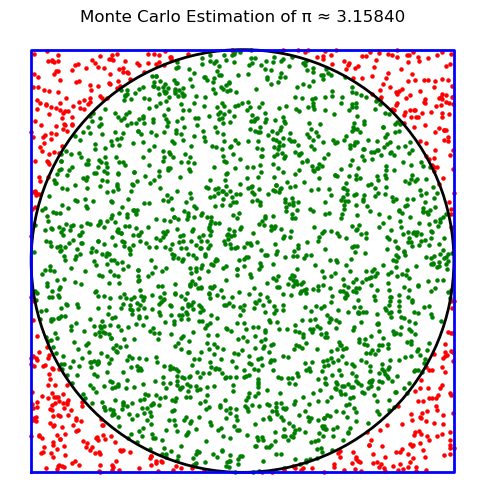

In [1]:
import numpy as np
import matplotlib.pyplot as plt
N=2500

x=2*np.random.rand(N)-1
y=2*np.random.rand(N)-1

inside=x^2 +y^2 <=1

pi_estimate=4*sum(inside)/N

plt.figure(figsize=(6,6))
plt.scatter(x[inside], y[inside], s=5, color='green')
plt.scatter(x[~inside], y[~inside], s=5, color='red')

from matplotlib.patches import Circle
circle = Circle((0,0), 1, fill=False, color='black', linewidth=2)
plt.gca().add_patch(circle)

plt.plot([-1,1,1,-1,-1], [-1,-1,1,1,-1], color='blue', linewidth=2)

plt.axis('equal')
plt.axis('off')

plt.title(f"Monte Carlo Estimation of π ≈ {float(pi_estimate):.5f}")
 
    
plt.show()

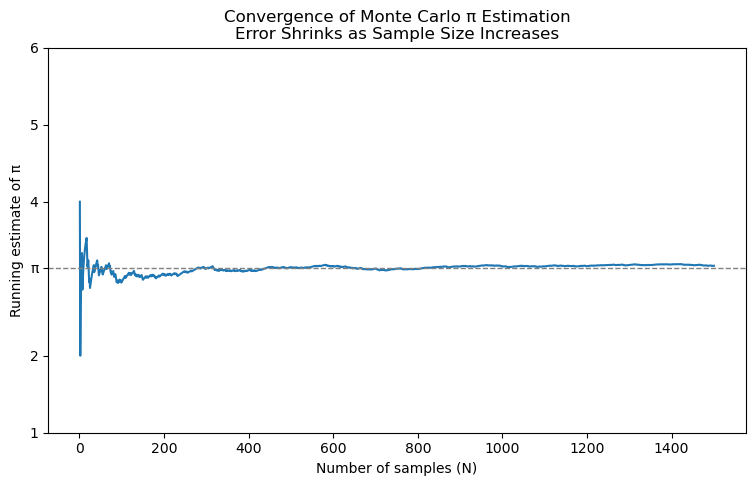

In [2]:
N = 1500
x = 2*np.random.rand(N) - 1
y = 2*np.random.rand(N) - 1
inside = x**2 + y**2 <= 1

running_pi = []
count_inside = 0
N_values=list(range(1,N+1))

for i in range(N):
    if inside[i]:
        count_inside += 1
    running_pi.append(4 * count_inside / (i+1))

plt.figure(figsize=(9,5))
plt.plot(N_values,running_pi)
plt.xlabel("Number of samples (N)")
plt.ylabel("Running estimate of π")

true_pi=np.pi
plt.axhline(np.pi, color='gray', linestyle='--', linewidth=1)

y_ticks = [6, 5, 4, true_pi, 2, 1]
y_labels = ["6", "5", "4", "π", "2", "1"]
plt.yticks(y_ticks, y_labels)

plt.title("Convergence of Monte Carlo π Estimation\nError Shrinks as Sample Size Increases")
plt.show()


### Understanding the Monte Carlo Convergence Graph 
The graph above is based on the $\pi$ estimation shown previously. It demonstrates clearly how the law of large numbers (LLN) affects the result of a calculation. The grey dotted line shows the actual value of $\pi$ and the blue line represent the estimated value of $\pi$ depending on the sample size.  As shown on the graph, the smallest sample size will experience the most fluctuation from the actual value estimated.The bigger the sample size is the closer to the actual value the result become.

Why the graph relates directly to Monte Carlo methods (Key takeaways)
- **Randomness is essential:** Each point acts like a “random experiment,” which is the foundation of Monte Carlo simulation.
- **More samples = less variability:** As shown, the smallest sample sizes fluctuate the most because the estimate is based on only a few random trials.
- **Monte Carlo convergence:** Large jumps for small $N$ and smoother behaviour for large $N$is the signature of Monte Carlo convergence.


## 1.1  In statistical terms
**What does "expected value" mean ?**

Many problems can be thought of as asking:

 “On average, what happens?”

For example:
- If the weather varies, what is the average temperature?
- If a stock goes up or down, what is the average return?
- If you roll a die, what is the average number you get?

The “average result in the long run” is what statisticians call the expected value.
We write it like this

$$\mu = \mathbb{E}[f(x)].$$

Here $x$ is a random input (e.g., a future stock return), and $f(x)$ is what we care about (ex: the payoff).  

This just means:

“If we could repeat this random situation millions of times, the long-term average would be $\mu$.”

**Monte Carlo estimator**

Monte Carlo replaces the impossible idea of repeating something millions of times by simulating it many times on the computer.

Each simulation uses a random input $x_i$ (like a random point, a random return, a random scenario).We compute whatever we care about (the payoff, the area, etc.),
 using $N$ independent samples $x_1,\dots,x_N$:

$$\hat\mu_N=\frac{1}{N}\sum_{i=1}^N f(x_i).$$

This is just mean to take many random experiments, calculate the result each time, and average them.That is the Monte Carlo estimator. The more random trials we use (larger $N$), the closer our estimate gets to the reality.

**Why the estimate is never exact**

Because each trial is random, the estimate wiggles around.
If we use few samples, the wiggles are large.
If we use many samples, the wiggles get small.

This is why the $\pi$ running-estimate graph jumps up and down at the beginning, then stabilizes.

**What a 95% confidence interval means** 

A 95% confidence interval tells you:

“Given the amount of randomness in our simulation, we are 95% confident the true answer lies in this range.”

We compute it as:$$\hat\mu_N\ \pm\ 1.96\cdot \frac{s}{\sqrt{N}}.$$

In simpler terms:
- The center of the interval is your estimate.
- The width of the interval shows how uncertain the estimate is.
- More samples $N$ $\rightarrow$ smaller interval $\rightarrow$ more precision.

You can think of it like:

_“How wide is the zone where the real answer probably is?”_
 
This communicates how precise the estimate is, given finite samples.


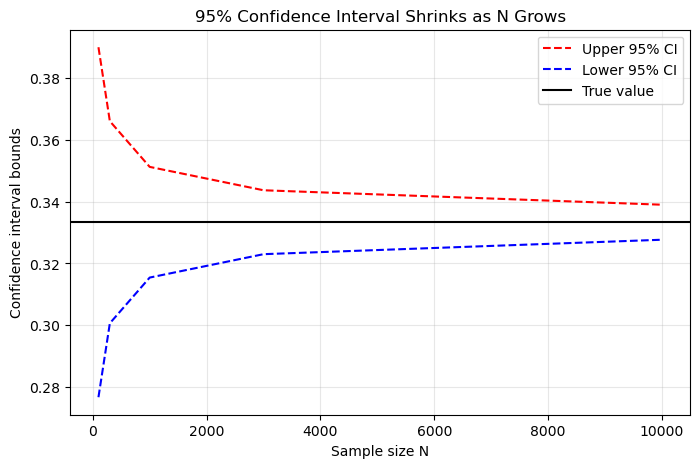

In [3]:
true_val = 1/3
N_values =[100, 300, 1000, 3000, 10000]
sigma = 1/np.sqrt(12) 
se = sigma/np.sqrt(N_values)

upper = true_val + 1.96*se
lower = true_val - 1.96*se

plt.figure(figsize=(8,5))
plt.plot(N_values, upper, 'r--', label="Upper 95% CI")
plt.plot(N_values, lower, 'b--', label="Lower 95% CI")
plt.axhline(true_val, color='black', label="True value")

plt.xlabel("Sample size N")
plt.ylabel("Confidence interval bounds")
plt.title("95% Confidence Interval Shrinks as N Grows")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### Graph explanation
This graph shows how our uncertainty band narrows as we collect more samples.
At small sample sizes the interval is wide because we don’t have much information.
As $N$ increases, the band tightens, meaning the Monte Carlo estimate becomes more reliable.

This confirms that LLN + CLT together control how accurately Monte Carlo performs.

## 2.0 Monte Carlo Aplications

## 2.1 The Monte Carlo simulation in finance

### The Vasicek Interest Rate Model

The **Vasicek model** describes how the short\-term interest rate evolves randomly over time, exhibiting a pullback toward its long\-run mean (mean reversion) and experiencing random shocks from the Brownian Motion.

The Brownian Motion represents the random, unpredictable movements that affect interest rates or stock prices. Every path starts at $W_0=0$ then each of them gets affected differently by different possible scenarios of random shocks.

This model assumes that the interest rates:

- They are volatile depending on economic conditions
- Never stay too low or too high 
- Do not wander too much upward or downward; they tend to return to a typical level over time (mean reversion)

This means that interest rates tend to fluctuate randomly, but in the long run, fluctuate toward an average, a phenomenon called mean reversion.



### The Vasicek Model Equation

The model is written as a stochastic\* differential equation:

$$
dr_t = a(b - r_t)dt + \sigma dW_t
$$

where:

- **$r_t$**: interest rate at time $t$
- **$a$**: speed of mean reversion (how quickly rates move back toward $b$)
- **$b$**: long\-term average interest rate
- **$\sigma$**: volatility (random shocks in the market)
- **$W_t$**: random, unpredictable shocks that affect the interest rates (Brownian motion)

**$a(b-r_t)dt**:$ Pulls $r_t$ toward b (the predictable part):
It represents **mean reversion**. 

If $r_t<b$: rates rise

If $r_t>b$: rates fall

 **$σdW_t$**: Adds randomness (the stochastic part)

*stochastic: something that evolves over time and whose future values cannot be predicted. 

---

### Monte Carlo Idea

The Monte Carlo simulation is used to generate multiple possible future scenarios of the short-term interest rate under the Vasicek model. 

It allows us to illustrate: 

- Mean inversion visually
- How volatility affects interest rates
- Realistic interest rate scenarios with randomness
- Uncertainty in short-term vs long-term rates



## Single Path Simulation:



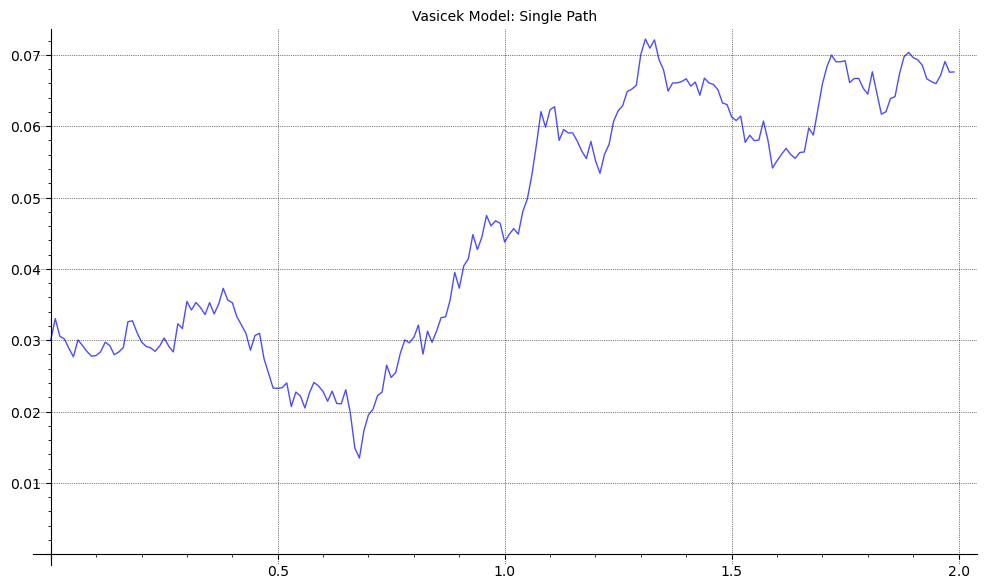

Total Paths: 1
Last random shock: 0.06593529351702272


In [4]:
import random
#Vasicek parameters
a = 0.5       #speed of mean reversion
b = 0.05      #long-term mean
sigma = 0.02  #volatility
r0 = 0.03     #initial short rate

T = 2         #total time in years
dt = 0.01
N = int(T/dt)
M = 1         #number of Monte Carlo paths


r_paths = [[r0 for j in range(N)] for i in range(M)]

#Monte Carlo simulation
for i in range(M):
    for j in range(1, N):
        u1 = random.random()
        u2 = random.random()
        
        z = random.gauss(0,1)  
        r_paths[i][j] = r_paths[i][j-1] + a*(b - r_paths[i][j-1])*dt + sigma*sqrt(dt)*z

#plot of one single path
p = plot(lambda x: 0, (0, T), color='white') 
for path in r_paths:
    points = [(k*dt, path[k]) for k in range(N)]
    p += list_plot(points, plotjoined=True, alpha=0.7, color='blue')

p.show(figsize=[10,6], gridlines=True, title="Vasicek Model: Single Path")

print(f"Total Paths: {M}")
print(f"Last random shock: {z}")

        


## How to interpret the graph

This plot shows the evolution of one simulated short-term interest rate path generated using the Vasicek model. The rate begins at an initial value of $r_0 = 0.03$ and then changes over time according to the forces of mean reversion and random market shocks, which together determine its movement.

- **Initial value:** The simulation begins at $r_0= 0.03$, representing today’s short\-term interest rate.

- **Step\-by\-step evolution:** At each time step, the model updates the rate using the Vasicek equation.

### Mean reversion

The path gradually moves toward the long-run mean $b = 0.05$.
This happens because of the term $a(b − rₜ)$, which “pulls” the interest rate:

- **Upward** when $r_t<b$
- **Downward** when $r_t>b$

This force represents the economic idea that interest rates do not drift endlessly—they tend to return to a stable long-run level.

### Random Shocks

The term $σ dW_t$ adds randomness to the path. 
These shocks represent unpredictable factors.

Because of these random shocks, the path does not move smoothly. Instead, it fluctuates, sometimes drifting away from the mean before being pulled back again.



## The Vasicek model with 50 paths:



In [5]:
import random

#Vasicek parameters
a = 0.5       #speed of mean reversion
b = 0.05      #long-term mean
sigma = 0.02  #volatility
r0 = 0.03     #initial short rate

T = 2 # of years
dt = 0.01
N = int(T/dt) #time steps: each time the interest rate moves
M = 50        #number of Monte Carlo paths

r_paths = []
for i in range(M):
    row = []
    for j in range(N):
        row.append(r0)
    r_paths.append(row)
    
#creates a list of lists for all paths, each path is a list of length N, and start with the initial rate r0

#Monte Carlo simulation in Sage
for i in range(M):
    
    for j in range(1, N):
        
        u1 = random.random()
        u2 = random.random()
        # u1 and u2 are unifrom random numbers between 0 and 1
        
        z = random.gauss(0,1) #the function gauss(0,1) generates a random number from a gaussian distribution, it represents a random shock term to approximate Brownian motion
        
        r_paths[i][j] = r_paths[i][j-1] + a*(b - r_paths[i][j-1])*dt + sigma*sqrt(dt)*z #adds the previous rate to the terms tat pulls toward the mean and a random fluctuation

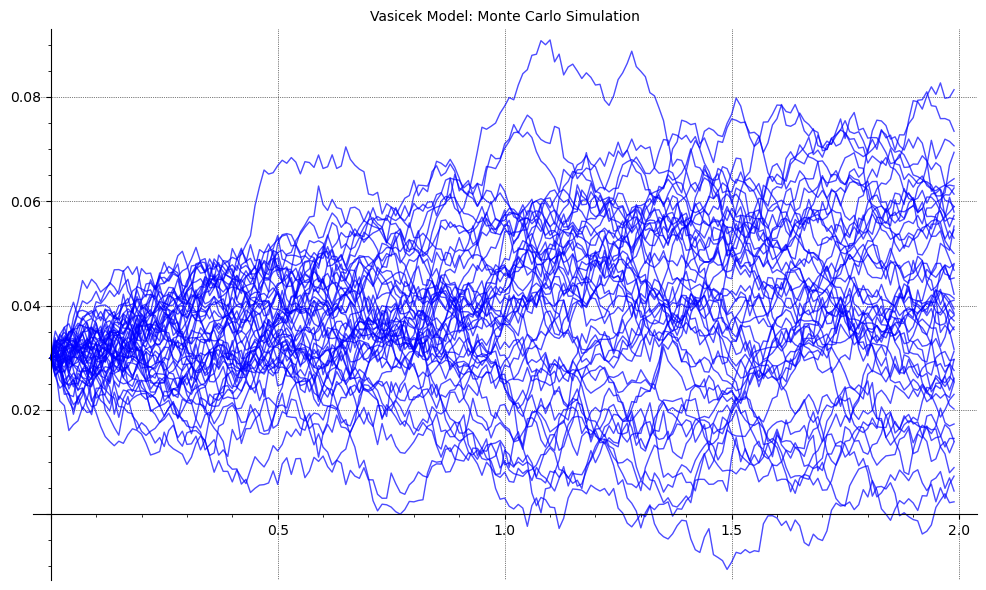

95% CI: (0.03462, 0.04542)
Total Paths: 50 
Total time: 2 years
Random shocks:-0.6898948746543453 


In [6]:

p = plot(lambda x: 0, (0, T), color='white')  

for path in r_paths:
    points = [(k*dt, path[k]) for k in range(N)]
    p += list_plot(points, plotjoined=True, alpha=0.7)

p.show(figsize=[10,6], gridlines=True, title="Vasicek Model: Monte Carlo Simulation")

# 95% confidence interval at final step:

n = len(r_paths) #list of all simulated paths

final_rates = [path[-1] for path in r_paths] # list of all last elements of each path
mean_final = sum(final_rates)/n #average of last interest rate of all paths

std_final = sqrt(sum((x - mean_final)**2 for x in final_rates)/(n-1)) # deviation of each final rate from average

print(f"95% CI: ({float(mean_final - 1.96*std_final/sqrt(n)):.5f}, {float(mean_final + 1.96*std_final/sqrt(n)):.5f})")

print(f"Total Paths: {M} ")
print(f"Total time: {T} years")
print(f"Random shocks:{z} ")

## How to interpret the graph

The graph shows 50 simulated paths over 2 years of short-term interest rates. Each line represents one possible future path of the short-term interest rate.

### Mean inversion explanation:

All paths fluctuate around the long\-term mean $b=0.05$.

- When a path rises **above** $b$, the term $a(b-r_t)$ pulls it **down**
- When a path rises **below** $b$. the same term pushes it **up**

This prevents interest rates from drifting to unrealistic levels and reflects the natural economic equilibrium that interest rates return to in the long run.

### Random shocks:

  Each time you rerun the code, the "random shocks" change.
  These shocks come from the stochastic term $σdW_t$ and represent unpredictable world effects such as:

- inflation surprises
- changes in the bond market
- shifts in investor expectations 
- global events
  They create short\-term volatility, which is why the simulated paths differ each time.

### Monte Carlo reasoning:

Monte Carlo simulation generates many possible future paths, each with different shocks.
This allows us to observe the range of possible outcomes, even when the future is uncertain and analytical solutions are not exact.

### The Confidence interval:

A 95% confidence interval means that 95% of all simulated paths will fall within a certain range. 

An example of the 95% confidence interval at the final time step can be:
$$[0.03584,0.04825]$$

This interval changes every time the code is rerun, but the statistical meaning stays the same: most paths end up inside this range, despite randomness.

### Economic application:

Banks, investment firms, insurance companies, and pension funds use the Vasicek model to:

- simulate realistic interest rate movements
- price government and corporate bonds
- estimate the cost of equity or capital
- measure interest rate risk
- plan long-term portfolios

It is especially useful because the market is so volatile and hard to predict.

### Why we use this model

- It prevents interest rates from exploding to infinity.
- It produces realistic short-term volatility with long-term stability.
- It is mathematically convenient for bond pricing.
- It provides a structured way to quantify risk in interest-rate-dependent assets.

**Example:**
A bank can use the Vasicek model to estimate the price of a 5-year government bond, using today’s interest rate and expected future volatility.




## 2.2 Architecture — Simulating Rays of Light Inside a Room (Diffuse Reflection)

**Goal:** 

Estimate how many rays will reah a certain point inside a room.

If we did this for multiple spots inside the room, it would demonstrates the darker and brighter spots when sunlight enters by the window.

**Context:**

When light rays hit a wall they reflect in every possible directions when the surface is rough at a microscopic level.

This phenomenon is called diffuse reflection.

This will be a simulation in 2D of diffuse reflection.


### 2D Lambertian Model

This model describes the behaviour of light when reflected on a rough surface.

It assume that, when light rays hit the rough surface, it diffuses equally in all directions. 

Also, Lambertian model is based on the fact that the light reflected is dependent only on the surface's normal and the light direction.

It is based on the formula: 
$$
P(θ)∝cos(θ)
$$

This model is used when dealing with the randomness of the angles after it bounced on the walls.


### Monte Carlo Idea

The direction of one ray, after it reflected on the wall, is given by a random angle (theta) between the normal and the ray.

We will simulate how many light rays pass through a certain point in a room.



In [7]:
import numpy as np
import matplotlib.pyplot as plt

#Generating random vector after it bounced on a wall

def random_direction(normal):
    
#create the unit vector

    n=normal/norm(normal)

# Lambertian Utilisation
    u=np.random.rand()
    theta=arcsin(u)
    if np.random.rand() < 0.5:
        side=1
    else:
        side=-1

    local_direction=vector([side*sin(theta),cos(theta)])
    tangent_vector=vector([-n[1],n[0]])

    return local_direction[0]*tangent_vector+local_direction[1]*n


In [8]:
def room(px, py, dx, dy, W, H):
#(px, py): where the ray is
#(dx, dy): direction it’s going
#(W, H): room boundaries
    hit_distances=[]

    if dy > 0:
        hit_top = (H - py) / dy
        if hit_top > 0: 
            hit_distances.append((hit_top, "top"))

    if dy < 0:
        hit_bottom = (0 - py) / dy
        if hit_bottom > 0:
            hit_distances.append((hit_bottom, "bottom"))

    if dx < 0:
        hit_left = (0 - px) / dx
        if hit_left > 0:
            hit_distances.append((hit_left, "left"))

    if dx > 0:
        hit_right = (W - px) / dx
        if hit_right > 0:
            hit_distances.append((hit_right, "right"))

    if len(hit_distances)==0:
        return None
    
    list_distances=[]
    for k in hit_distances:
        list_distances.append(k[0])
        
    distance_min=min(list_distances)
    
    for k in hit_distances:
        if k[0]==distance_min:
            name=k[1]
    
    return distance_min, name

In [9]:
def wall_normal(wall):
    return {
    "top":vector([0, -1]),
    "bottom":vector([0,  1]),
    "left":vector([1,  0]),
    "right":vector([-1, 0])
}[wall]


In [10]:
def monte_carlo_rays(
    N=300,
    W=8,
    H=6,
    window=(3,5),
    sun_angle=-30,
    bounces=3,
):

    target_x=6.5
    target_y=5        
    tolerance=0.5         
    hit_count=0
    
    plt.figure(figsize=(7,5))

    for k in range(N):

# Light entry Point

        x=0
        y=np.random.uniform(window[0], window[1])
        
# Considering the sun is far far away, 
# all incoming rays are parallel  

        sun_angle_rad=sun_angle * pi/180
        dx=cos(sun_angle_rad)
        dy=sin(sun_angle_rad)

# First segment color

        color="orange"

# Bounce loop
        
        for b in range(bounces+1):

            hit_distance=room(x, y, dx, dy, W, H)
            if hit_distance==None:
                break

            x2=x+dx*hit_distance[0]
            y2=y+dy*hit_distance[0]

# Draw segment

            plt.plot([x, x2], [y, y2], color=color, linewidth=0.4,zorder=4-b)
    
## Check if light rays pass close enough to the point

            for t in [0, 0.25, 0.5, 0.75, 1]:
                sx=x+t*(x2 - x)
                sy=y+t*(y2 - y)
                d=float(sqrt((sx - target_x)**2+(sy - target_y)**2))
                if d<tolerance:
                    hit_count+=1
                    break
            
# Updated starting coordinates

            x, y = x2, y2

# Random Bounce Direction

            new_vector=wall_normal(hit_distance[1])
            dx,dy=random_direction(new_vector)
            colors=['royalblue','lime','hotpink','black']
            color=colors[b]            

# Plot the room

    plt.plot([0,W,W,0,0], [0,0,H,H,0], 'black', lw=2)
    plt.plot([0,0], [window[0], window[1]], 'cyan', lw=4)
    plt.scatter(6.5,5,color='red',zorder=10)
    plt.xlim(-1, W+1)
    plt.ylim(-1, H+1)
    plt.title("Monte Carlo Ray Simulation")

    print(f"Total rays: {N}")
    print(f"Estimated Hits: {hit_count}")
    
    plt.show()

Total rays: 1
Estimated Hits: 0


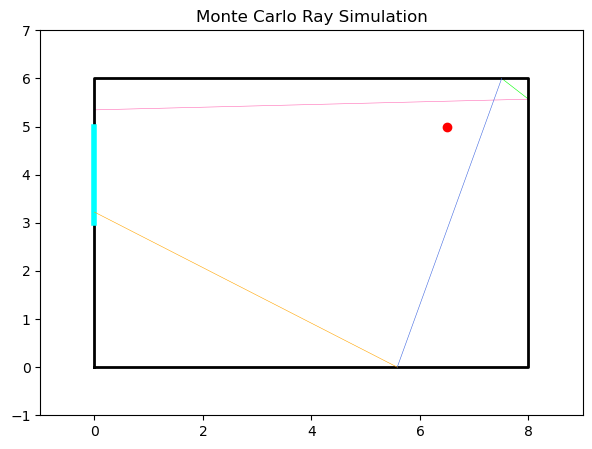

In [11]:
monte_carlo_rays(N=1)

Total rays: 300
Estimated Hits: 30


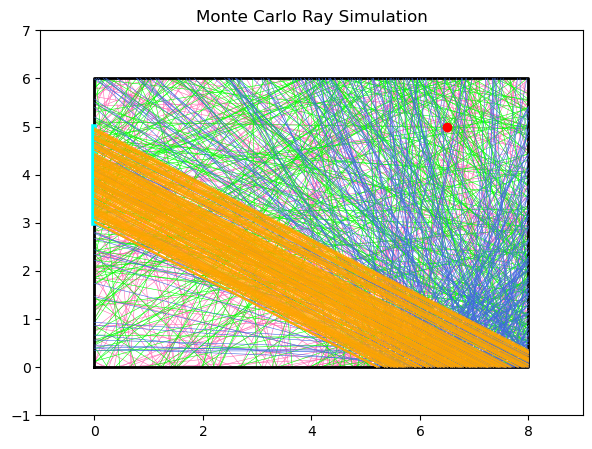

In [12]:
monte_carlo_rays()

### How to Interprete the Graph

The graph shows 300 light rays entering by a window. 

Some of them reach a fixed point in the room. 

If we repeat this simulation with other points in the room, it would allow for the estimation of where the light will be most and least present in the room showing where the shadows most likely will appear during daytime.

**Monte Carlo Reasoning:**  

- We simulated 300 light rays entering by a window.  

- For each, we computed their trajectories to see if they reach the fixed point inside the room.

- Averaging all these values (of number of rays reaching the point) gives the expected light intensity at that point in the room. 

- Here, the sample is relatively small (300 light rays). The Monte Carlo simulation would be way more precise if we used way more light rays. However, for the purpose of making the graph easier to understand, we chose to make the sample smaller meaning the estimation is further from the true value of number of light rays passing throught the point.

**Architecture Application:**

In architecture, the lighting in a room is very important.

This kind of simulation could be used to test different windows positions in a room to visualize which would have the best possible lighting.

There are better ways to evaluate diffuse reflection in a room.

However, it is still relevant to do it using Monte Carlo simulation in the context of this particular project. 





## 2.3 Reliability Engineering \- Simulating System Failure Probability

**Goal:** 

The Monte Carlo beam model describes how the stress in a structural beam changes due to uncertainty in loading, material properties, and manufacturing dimensions. Instead of assuming one fixed value for each parameter, the model treats them as random variables, reflecting the real\-world variability that engineers encounter.

Small variations in load, material strength, or section dimensions can cause stresses to fluctuate. Some beams will be stronger, some weaker, some heavier, some lighter—each “scenario” behaves differently depending on its random characteristics.

These random variations can be :

- differences in steel quality from batch to batch
- changes in the applied load
- manufacturing tolerances in beam height and width
- unexpected real\-world conditions (such as corrosion or material degradation)
- measurement uncertainty  



### Monte Carlo Beam Failure Model

**The stress can be verified using the following equation** : 

The bending stress in the beam is computed using:

$$
\sigma = \frac{6WL^2}{b h^2}
$$

​

where:

$W$ : applied load (in N)

$L$ : beam length (in m)

$b$ : beam width (in m)

$h$ : beam height (in m)

$\sigma$ : bending stress (in Pa or $N/m^2$)

The equation shows that a few variables could be responsible for the stress level on a material such as an higher load, a smaller width/height or a bigger length. To get these variables, the most extended form of the equation was used including the variations for a rectangular beam.To determine if a material will break, the bending stress is compared to the **Yield Strength** ($\sigma_Y$) , which is defined by the maximum stress a material can withstand without undergoing permanent shape change (deformation). Failure of a material occurs if : 

$$
\sigma > \sigma_Y
$$

​For the following code, some variables need to be selected from real life standards such as any element for the use of steel in engineering since it is the material chosen for this example, A36 steal was chosen for the $\sigma_Y$ , which is around 250 MPa (source 4).


Estimated Probability of Failure: 0.3548 (35.48%)


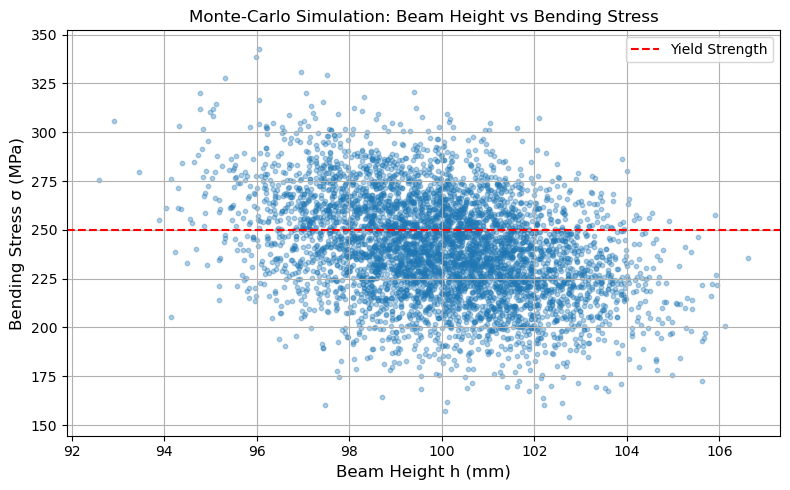

In [13]:
import numpy as np
import matplotlib.pyplot as plt

# Number of random samples/possile scenarios
N = 5000  


# Constant variables 
L = 2.0        # Beam length (m)
b = 0.05       # Width (m)
sigma_yield = 250  # MPa (for reference line)

# Random variables (variable, standart deviation/uncertainty)
h = np.random.normal(loc=0.10, scale=0.002, size=N)      # Height (0.10 m, 0.002 m)
W = np.random.normal(loc=5000, scale=500, size=N)        # Load (5000 N, 500 N)



# Stress calculation with formula, sigma = (6 W L^2)/(b h^2)
sigma = (6 * W * L**2) / (b * h**2)      # Stress in Pa

# Convertion of units for better view in the graph
h_mm = h * 1000               # mm
sigma_MPa = sigma / 1e6       # MPa

# Probability of failure (occurs when stress > yield stress)
failures = sigma_MPa > sigma_yield
prob_failure = np.sum(failures) / N

print(f"Estimated Probability of Failure: {prob_failure:.4f} ({prob_failure*100:.2f}%)")


# Plot of height vs stress
plt.figure(figsize=(8, 5))
plt.scatter(h_mm, sigma_MPa, s=10, alpha=0.35)

plt.xlabel("Beam Height h (mm)", fontsize=12)
plt.ylabel("Bending Stress σ (MPa)", fontsize=12)
plt.title("Monte-Carlo Simulation: Beam Height vs Bending Stress")

# Yield strength line
plt.axhline(y=sigma_yield, color='red', linestyle='--', label="Yield Strength")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

### Graph explanation:

**What each point represents** : Each dot on the plot represents one possible real\-world scenario for the beam. For each scenario, a random beam height $h$ and a random load $W$ is selected by the program from the normal distribution to compute the bending stress created by the change. 

**The influence of height** : This graph really helps understand how much influence small changes in height can have on a beam. Since the height is squared in the formula for stress, its impact has a lot of importance on the durability of the material. What we can observe is that:

- Smaller height carries a lot more stress since they are thinner making them more easily bendable
- Bigger height representing thicker beams reduce the amount of stress the material is on, helping it resist bending.

This is easily observable even with the shape of the cloud since it has a tendency to inch downward the larger the height gets.

**Why the red line is important** : In this scenario, the red line represents the **Yield Strength** ($\sigma_Y$)   of the material. As chosen earlier, the value is of 250 MPa for A36 steal. Therefore, all the point above the red line represent cases of failure where the material breaks and all the point below show safe scenarios.

Another way to show failure is to directly compare the yield strength with the bending stress as shown with the following graph.



Estimated probability of failure = 0.37049


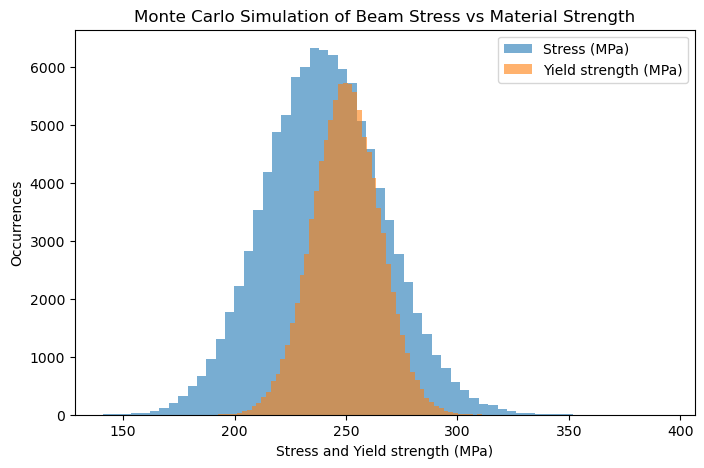

In [14]:
import numpy as np
import matplotlib.pyplot as plt


N = 100000 # Number of random samples/possile scenarios
L = 2.0 # Beam length (2 meters/does not vary)  


# Random variables (variable, standart deviation/uncertainty)
W      = np.random.normal(5000, 500, N)    # Load (N)
sigmaY = np.random.normal(250e6, 15e6, N)    # Yield strength (MPa)
b      = np.random.normal(0.05, 0.001, N)    # Width (in meters)
h      = np.random.normal(0.10, 0.002, N)    # Height (in meters)


# Stress calculation with formula, sigma = (6 W L^2)/(b h^2)
sigma = (6 * W * L**2) / (b * h**2)


# Failure check 
failure = sigma > sigmaY
prob_failure = np.mean(failure)  # Average failures

print("Estimated probability of failure =", prob_failure)


# Plot of stress vs strength 
plt.figure(figsize=(8,5))
plt.hist(sigma/1e6, bins=60, alpha=0.6, label="Stress (MPa)")
plt.hist(sigmaY/1e6, bins=60, alpha=0.6, label="Yield strength (MPa)")
plt.xlabel("Stress and Yield strength (MPa)")
plt.ylabel("Occurrences")
plt.legend()
plt.title("Monte Carlo Simulation of Beam Stress vs Material Strength")
plt.show()

### Graph explanation:

**Occurrences (y\-axis)** : Represent how many of the 100,000 simulated values fall into each section.

**Why does the graph change each time** : The load, the width and the height are variables that are randomly selected around their uncertainties making the curves shift, showing how small differences can greatly affect the reliability of the material.

**What does the overlap region represent** : When the curves overlap, it show that the bending stress is bigger than the yield strength ( $\sigma>\sigma_Y$ ). In these cases, the chances for the beam to break are high meaning that: 

- the stress is too high 
- or the steel is too weak

In cases where the blue curve representing the stress is completely to the left of the orange strength curve, there is technically no chances of the beam breaking.



## Bibliography and References

**Web & Technical Resources**

1. NumPy Documentation._ https://numpy.org/doc/

2. Chatgpt (for research and understanding the statistical knowledge) [chatgpt.com](http://chatgpt.com)

3. ScienceDirect (Lambertian Model). [https://www.sciencedirect.com/topics/computer\-science/lambertian\-model](https://www.sciencedirect.com/topics/computer-science/lambertian-model)

4. Boulon Eclair:[https://boulonseclair.com/pages/structural\-steel\-grades\-strength](https://boulonseclair.com/pages/structural-steel-grades-strength) 

5. Omni calculator:[https://www.omnicalculator.com/construction/bending\-stress](https://www.omnicalculator.com/construction/bending-stress) 

6. GBM Notes: www.math.kent.edu/~reichel/courses/intr.num.comp.2/lecture23/old/gbm.pdf

7. Investopedia: www.investopedia.com/terms/v/vasicek-model.asp

8. AnalystPrep: www.analystprep.com/study-notes/frm/part-2/market-risk-measurement-and-management/the-vasicek-and-gauss-models

9.  SSRN: https://papers.ssrn.com/abstract=2479671

### 🎥 YouTube / Multimedia Sources

10. **MarbleScience.** _Monte Carlo Simulation._ YouTube, 8 Sep 2020.  
   [https://www.youtube.com/watch?v=7ESK5SaP\-bc](https://www.youtube.com/watch?v=7ESK5SaP-bc)  
   _(Explains the core idea of Monte Carlo simulation with clear visuals.)_

11. **IBM Technology.** _What is Monte Carlo Simulation?_ YouTube, 8 Jul 2022.  
   https://www.youtube.com/watch?v=7TqhmX92P6U  
   _(Gives an overview of how Monte Carlo is applied in finance and engineering.)_

12. **Very Normal.** _Crash Course on Monte Carlo Simulation._ YouTube, 3 Feb 2023.  
   https://www.youtube.com/watch?v=OdWLP8umw3A

 ---

*(All references were consulted between November 2025 and December 2025.)*

